<div style="background-color: steelblue; padding: 10px; border-radius: 5px;">
    <p style="margin: 10;"></p>
    <h1 style="text-align: center; margin: 0; font-weight: bold; color: white;">SWOT OMIP : MODELS/SWOT Ratio</h1>
    <p style="margin: 10;"></p>
</div>


## 📦**Imports** 

In [29]:
%%time

##################################
#Imports

from datetime import datetime
import s3fs
import xarray as xr
import pyinterp
from widetrax import DataPreprocessing as dp
from widetrax import Spectra as sp
import numpy as np
import json
from watermark import watermark
import time
import platform
from shapely.geometry import shape, box

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

import plot_psd1Xglobal1 as pp2X
import position_function as pf
import cum_sp_onl_season_v3 as cs
import importlib
importlib.reload(cs)

CPU times: user 3.57 ms, sys: 2.26 ms, total: 5.83 ms
Wall time: 6.17 ms


<module 'cum_sp_onl_season_v3' from '/Users/contrema/Documents/Postdoc/SWOTv2/cum_sp_onl_season_v3.py'>

## **Load boxes position**

In [30]:
boxesjson="mostly_ocean_boxes_filtered.geojson"
north_boxes, south_boxes=pf.position_boxes_northsouth(boxesjson)
selected=pf.position_boxes(boxesjson) # Index boxes for global ocean, and the region



North boxes: 93
South boxes: 189


## **Estimation of models/swot ratio**


In [31]:
models=["GLO12V4","GLO36V1","GLO36V1NOTIDE","NOC12","NOC025","LLC4320","SWOT"]
wmin=50
wmax=500
# Winter ratio
RW,FW=cs.ratio_model(models, selected, wmin, wmax, north_boxes, south_boxes, "https://minio.dive.edito.eu/",
                "JFM", "JAS","winter","SWOT")
# Summer ratio
RS,FS=cs.ratio_model(models, selected, wmin, wmax, north_boxes, south_boxes, "https://minio.dive.edito.eu/",
                "JFM", "JAS","summer","SWOT")

/Users/contrema/Documents/Postdoc/SWOTv2/cum_sp_onl_season_v3.py:392: RuntimeWarning: divide by zero encountered in divide
  wavelength = 1.0 / freq
/Users/contrema/Documents/Postdoc/SWOTv2/cum_sp_onl_season_v3.py:425: RuntimeWarning: divide by zero encountered in divide
  wavelength = 1.0 / freq


## Estimation Rossy deformation

In [32]:
#LOAD DATA

dng = xr.open_dataset('/Users/contrema/Documents/Postdoc/Data/Rossby_radius.nc')
c1=dng['c1'][:].data
latR=dng['lat'][:].data
dng.close()

omega = 7.292e-5 
f = 2 * omega * np.sin(np.deg2rad(latR))

RoR=np.nanmean(c1/f,axis=0)/1000

poslatR=np.where((latR>=-3) & (latR <=3))
RoR[poslatR]=np.nan

/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_33363/1088865816.py:11: RuntimeWarning: divide by zero encountered in divide
  RoR=np.nanmean(c1/f,axis=0)/1000
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_33363/1088865816.py:11: RuntimeWarning: invalid value encountered in divide
  RoR=np.nanmean(c1/f,axis=0)/1000


## Organizing boxes by latitude (to estimate the zonal average

In [33]:
with open("mostly_ocean_boxes_filtered.geojson") as f:
    data = json.load(f)

latboxes = []
latpos=np.arange(-70,61,10)

for i, feature in enumerate(data["features"]):
    coords = feature["geometry"]["coordinates"][0]
    first_lat = coords[0][1]  # First coord [lon, lat] → lat is index 1
    latboxes.append(first_lat)

latindex=[]
for i in latpos:
    latindex.append(np.where(latboxes==i))

print(latindex[0])


(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24]),)


## Plotting zonal averaged of the models swot ratio

/opt/anaconda3/envs/s3env/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/envs/s3env/lib/python3.14/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/opt/anaconda3/envs/s3env/lib/python3.14/site-packages/numpy/_core/_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/envs/s3env/lib/python3.14/site-packages/numpy/_core/_methods.py:178: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/opt/anaconda3/envs/s3env/lib/python3.14/site-packages/numpy/_core/_methods.py:211: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


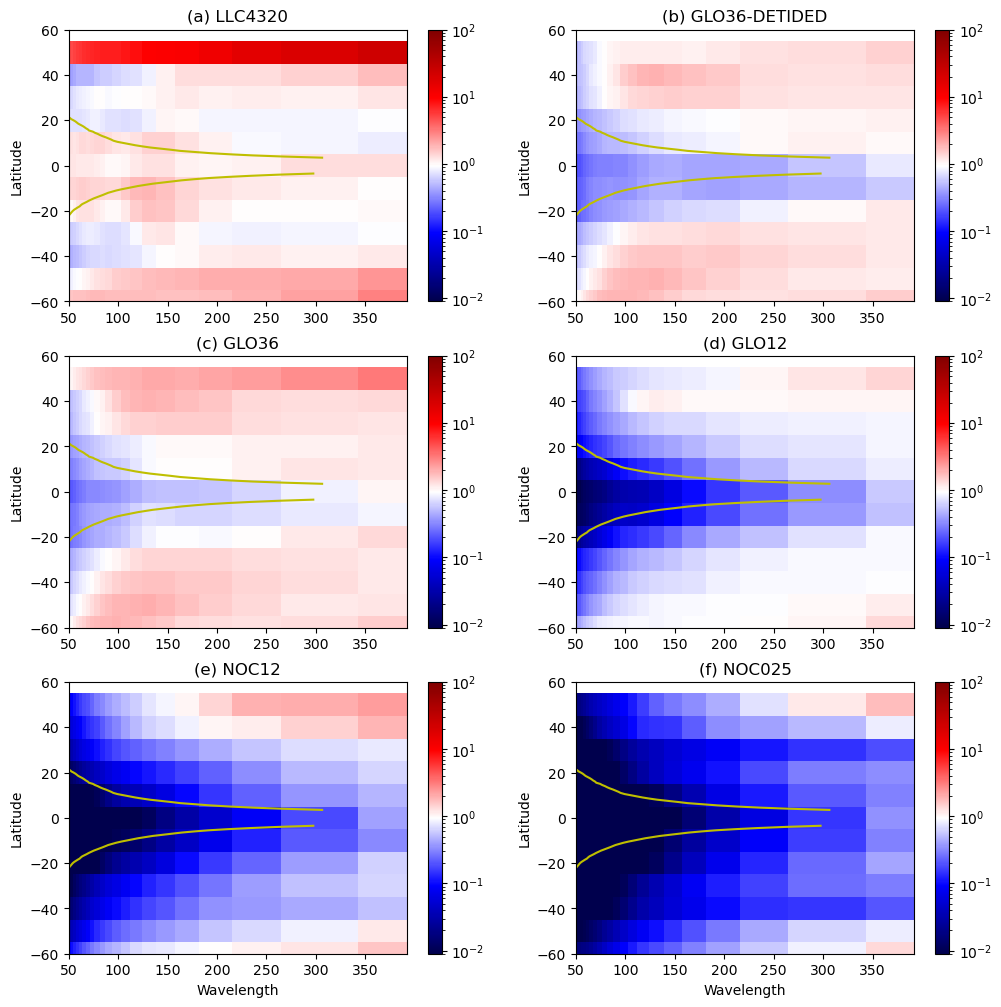

In [34]:
#----------------
# WINTER
#--------------
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

modelslabel=["GLO12","GLO36","GLO36-DETIDED","NOC12","NOC025","LLC4320"]
models=["GLO12V4","GLO36V1","GLO36V1NOTIDE","NOC12","NOC025","LLC4320"]

#---------

F2 = FW[models[0]]
Wl=np.squeeze(F2[0]) #à

Fmean=np.zeros((len(Wl),len(latindex),len(models)))
Fstd=np.zeros((len(Wl),len(latindex),len(models)))

kmod=0
for imodel in models:
    RM=RW[imodel]
    for i in range(len(latindex)): #len(R)):
        k=0
        pos=latindex[i][0]
        #Fb0 = np.zeros(len(Wl))
        #Fstd = np.zeros(len(Wl))

        F_interp = []

        for ilat in pos:
            F_interp.append(
                np.interp(Wl, np.squeeze(F2[ilat]), np.squeeze(RM[ilat]))
            )
            k += 1
        F_interp = np.array(F_interp)
        Fmean[:, i, kmod] = np.mean(F_interp, axis=0)  # Mean
        Fstd[:, i, kmod] = np.std(F_interp, axis=0)  # Standard deviation (population)

    kmod=kmod+1

#------
mymin=1e2
mymax=1e-2
norm = mcolors.LogNorm(vmin=mymin, vmax=mymax)

imodel=5
fig, ax = plt.subplots(3, 2,figsize=(12, 12))   
pc=ax[0,0].pcolormesh(1/Wl,latpos, np.squeeze(Fmean[:,:,imodel]).T, norm=norm,shading='nearest',cmap='seismic')
ax[0,0].plot( np.abs(RoR),latR,color='y')
ax[0,0].set_ylabel("Latitude")
ax[0,0].set_ylim([-60,60])
ax[0,0].set_xlim([50,np.nanmax(1/Wl)])
ax[0,0].set_title("(a) "+ modelslabel[imodel])
fig.colorbar(pc,ax=ax[0,0])

imodel=2
pc=ax[0,1].pcolormesh(1/Wl,latpos, np.squeeze(Fmean[:,:,imodel]).T,norm=norm,shading='nearest',cmap='seismic')
#ax[0,1].set_xlabel("Wavelength")
ax[0,1].plot( np.abs(RoR),latR,color='y')
ax[0,1].set_ylabel("Latitude")
ax[0,1].set_ylim([-60,60])
ax[0,1].set_xlim([50,np.nanmax(1/Wl)])
ax[0,1].set_title("(b) "+ modelslabel[imodel])
fig.colorbar(pc,ax=ax[0,1])

imodel=1
pc=ax[1,0].pcolormesh(1/Wl,latpos, np.squeeze(Fmean[:,:,imodel]).T,norm=norm,shading='nearest',cmap='seismic')
#ax[1,0].set_xlabel("Wavelength")
ax[1,0].plot( np.abs(RoR),latR,color='y')
ax[1,0].set_ylabel("Latitude")
ax[1,0].set_ylim([-60,60])
ax[1,0].set_xlim([50,np.nanmax(1/Wl)])
ax[1,0].set_title("(c) "+ modelslabel[imodel])
fig.colorbar(pc,ax=ax[1,0])

imodel=0
pc=ax[1,1].pcolormesh(1/Wl,latpos, np.squeeze(Fmean[:,:,imodel]).T,norm=norm,shading='nearest',cmap='seismic')
#ax[1,1].set_xlabel("Wavelength")
ax[1,1].plot( np.abs(RoR),latR,color='y')
ax[1,1].set_ylabel("Latitude")
ax[1,1].set_ylim([-60,60])
ax[1,1].set_xlim([50,np.nanmax(1/Wl)])
ax[1,1].set_title("(d) "+ modelslabel[imodel])
fig.colorbar(pc,ax=ax[1,1])

imodel=3
pc=ax[2,0].pcolormesh(1/Wl,latpos, np.squeeze(Fmean[:,:,imodel]).T,norm=norm,shading='nearest',cmap='seismic')
ax[2,0].set_xlabel("Wavelength")
ax[2,0].plot( np.abs(RoR),latR,color='y')
ax[2,0].set_ylabel("Latitude")
ax[2,0].set_ylim([-60,60])
ax[2,0].set_xlim([50,np.nanmax(1/Wl)])
ax[2,0].set_title("(e) "+ modelslabel[imodel])
fig.colorbar(pc,ax=ax[2,0])

imodel=4
pc=ax[2,1].pcolormesh(1/Wl,latpos, np.squeeze(Fmean[:,:,imodel]).T,norm=norm,shading='nearest',cmap='seismic')
ax[2,1].set_xlabel("Wavelength")
ax[2,1].plot( np.abs(RoR),latR,color='y')
ax[2,1].set_ylabel("Latitude")
ax[2,1].set_ylim([-60,60])
ax[2,1].set_xlim([50,np.nanmax(1/Wl)])
ax[2,1].set_title("(f) "+ modelslabel[imodel])
fig.colorbar(pc,ax=ax[2,1])
#plt.savefig("FigV2/meanlatratio_modelsswot_winter_v2.png",dpi=300,transparent=False)




plt.show()


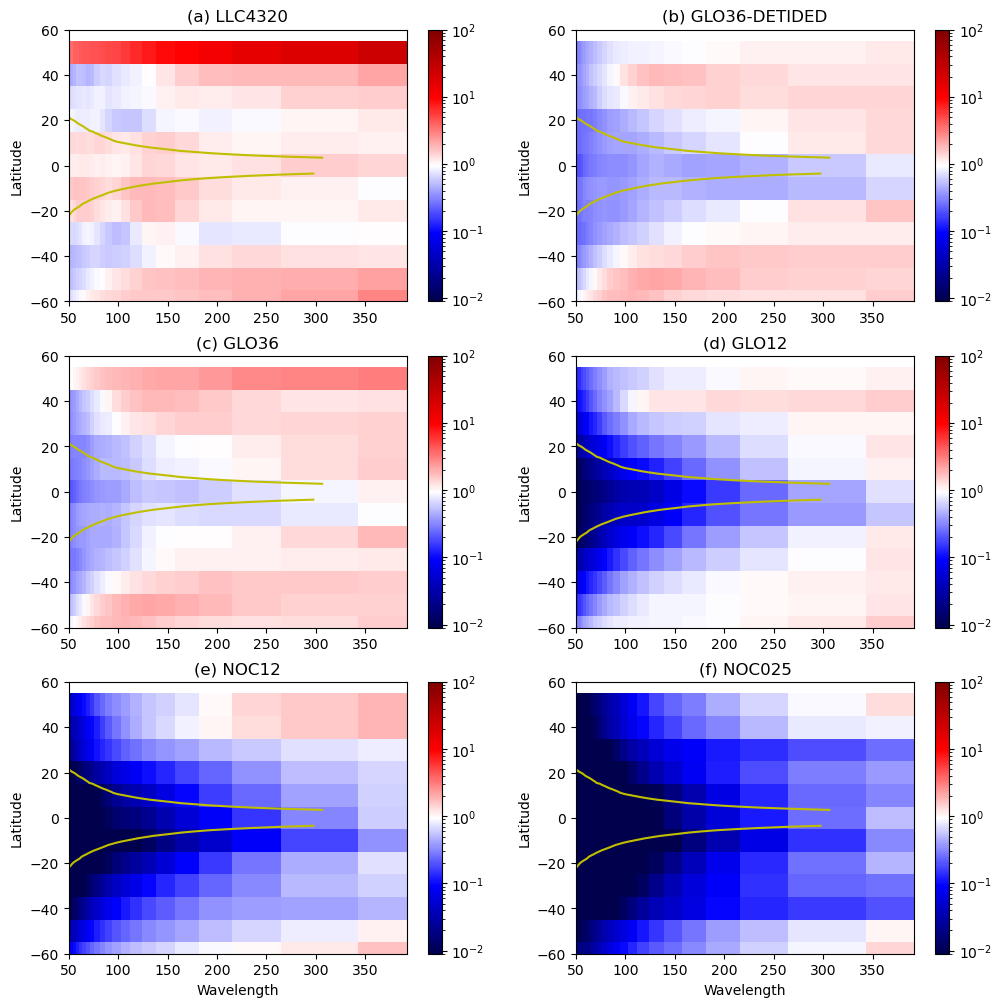

In [35]:
#----------------
# SUMER
#--------------
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

modelslabel=["GLO12","GLO36","GLO36-DETIDED","NOC12","NOC025","LLC4320"]
models=["GLO12V4","GLO36V1","GLO36V1NOTIDE","NOC12","NOC025","LLC4320"]

#---------

F2 = FS[models[0]]
Wl=np.squeeze(F2[0]) #à

Fmean=np.zeros((len(Wl),len(latindex),len(models)))
Fstd=np.zeros((len(Wl),len(latindex),len(models)))

kmod=0
for imodel in models:
    RM=RS[imodel]
    for i in range(len(latindex)): #len(R)):
        k=0
        pos=latindex[i][0]
        #Fb0 = np.zeros(len(Wl))
        #Fstd = np.zeros(len(Wl))

        F_interp = []

        for ilat in pos:
            F_interp.append(
                np.interp(Wl, np.squeeze(F2[ilat]), np.squeeze(RM[ilat]))
            )
            k += 1
        F_interp = np.array(F_interp)
        Fmean[:, i, kmod] = np.mean(F_interp, axis=0)  # Mean
        Fstd[:, i, kmod] = np.std(F_interp, axis=0)  # Standard deviation (population)

    kmod=kmod+1

#------
mymin=1e2
mymax=1e-2
norm = mcolors.LogNorm(vmin=mymin, vmax=mymax)

imodel=5
fig, ax = plt.subplots(3, 2,figsize=(12, 12))   
pc=ax[0,0].pcolormesh(1/Wl,latpos, np.squeeze(Fmean[:,:,imodel]).T, norm=norm,shading='nearest',cmap='seismic')
ax[0,0].plot( np.abs(RoR),latR,color='y')
ax[0,0].set_ylabel("Latitude")
ax[0,0].set_ylim([-60,60])
ax[0,0].set_xlim([50,np.nanmax(1/Wl)])
ax[0,0].set_title("(a) "+ modelslabel[imodel])
fig.colorbar(pc,ax=ax[0,0])

imodel=2
pc=ax[0,1].pcolormesh(1/Wl,latpos, np.squeeze(Fmean[:,:,imodel]).T,norm=norm,shading='nearest',cmap='seismic')
#ax[0,1].set_xlabel("Wavelength")
ax[0,1].plot( np.abs(RoR),latR,color='y')
ax[0,1].set_ylabel("Latitude")
ax[0,1].set_ylim([-60,60])
ax[0,1].set_xlim([50,np.nanmax(1/Wl)])
ax[0,1].set_title("(b) "+ modelslabel[imodel])
fig.colorbar(pc,ax=ax[0,1])

imodel=1
pc=ax[1,0].pcolormesh(1/Wl,latpos, np.squeeze(Fmean[:,:,imodel]).T,norm=norm,shading='nearest',cmap='seismic')
#ax[1,0].set_xlabel("Wavelength")
ax[1,0].plot( np.abs(RoR),latR,color='y')
ax[1,0].set_ylabel("Latitude")
ax[1,0].set_ylim([-60,60])
ax[1,0].set_xlim([50,np.nanmax(1/Wl)])
ax[1,0].set_title("(c) "+ modelslabel[imodel])
fig.colorbar(pc,ax=ax[1,0])

imodel=0
pc=ax[1,1].pcolormesh(1/Wl,latpos, np.squeeze(Fmean[:,:,imodel]).T,norm=norm,shading='nearest',cmap='seismic')
#ax[1,1].set_xlabel("Wavelength")
ax[1,1].plot( np.abs(RoR),latR,color='y')
ax[1,1].set_ylabel("Latitude")
ax[1,1].set_ylim([-60,60])
ax[1,1].set_xlim([50,np.nanmax(1/Wl)])
ax[1,1].set_title("(d) "+ modelslabel[imodel])
fig.colorbar(pc,ax=ax[1,1])

imodel=3
pc=ax[2,0].pcolormesh(1/Wl,latpos, np.squeeze(Fmean[:,:,imodel]).T,norm=norm,shading='nearest',cmap='seismic')
ax[2,0].set_xlabel("Wavelength")
ax[2,0].plot( np.abs(RoR),latR,color='y')
ax[2,0].set_ylabel("Latitude")
ax[2,0].set_ylim([-60,60])
ax[2,0].set_xlim([50,np.nanmax(1/Wl)])
ax[2,0].set_title("(e) "+ modelslabel[imodel])
fig.colorbar(pc,ax=ax[2,0])

imodel=4
pc=ax[2,1].pcolormesh(1/Wl,latpos, np.squeeze(Fmean[:,:,imodel]).T,norm=norm,shading='nearest',cmap='seismic')
ax[2,1].set_xlabel("Wavelength")
ax[2,1].plot( np.abs(RoR),latR,color='y')
ax[2,1].set_ylabel("Latitude")
ax[2,1].set_ylim([-60,60])
ax[2,1].set_xlim([50,np.nanmax(1/Wl)])
ax[2,1].set_title("(f) "+ modelslabel[imodel])
fig.colorbar(pc,ax=ax[2,1])
#plt.savefig("FigV2/meanlatratio_modelsswot_summer_v2.png",dpi=300,transparent=False)




plt.show()
